# Credit Card Fraud Detection

Identify rare fraudulent transactions while showing the trade-off between missed fraud and investigation workload.

Only 16 fraud cases occur in the test sample and 8 in validation. The observed recall and chosen threshold therefore have substantial sampling uncertainty. Two days of anonymized 2013 transactions cannot establish production performance.

## Reproduce the workflow

Install `requirements-dev.txt` into your Python environment, then run this notebook from the repository. No database, Databricks, S3 mount, or credentials are required.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
from fetch_data import fetch
from analysis import run, ROOT
fetch()

Verified existing input: data/transactions.csv


## Source and input checks

A 50,000-row stratified sample (seed 42) of the deduplicated Worldline/ULB benchmark: 49,917 legitimate and 83 fraudulent transactions. The original has 284,807 rows and 492 frauds; removing 1,081 exact duplicate records precedes sampling. This is a public anonymized transaction benchmark, not synthetic data. The download URL is documented in TensorFlow's official [imbalanced-classification tutorial](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data).

In [2]:
data = pd.read_csv(ROOT / 'data/transactions.csv')
print('Rows and columns:', data.shape)
display(data.head())
display(data['Class'].value_counts().rename('label_count'))

Rows and columns: (50000, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
1,10.0,1.249999,-1.221637,0.383930,-1.234899,-1.485419,-0.753230,-0.689405,-0.227487,-2.094011,...,-0.231809,-0.483285,0.084668,0.392831,0.161135,-0.354990,0.026416,0.042422,121.50,0
2,10.0,0.384978,0.616109,-0.874300,-0.094019,2.924584,3.317027,0.470455,0.538247,-0.558895,...,0.049924,0.238422,0.009130,0.996710,-0.767315,-0.492208,0.042472,-0.054337,9.99,0
3,12.0,1.103215,-0.040296,1.267332,1.289091,-0.735997,0.288069,-0.586057,0.189380,0.782333,...,-0.024612,0.196002,0.013802,0.103758,0.364298,-0.382261,0.092809,0.037051,12.99,0
4,18.0,1.166616,0.502120,-0.067300,2.261569,0.428804,0.089474,0.241147,0.138082,-0.989162,...,0.018702,-0.061972,-0.103855,-0.370415,0.603200,0.108556,-0.040521,-0.011418,2.28,0


Class
0    49917
1       83
Name: label_count, dtype: int64

## Evaluation design

Chronological train/validation/test partitions; Time is excluded as a predictor. Compare class-weighted logistic regression and a bounded random forest. Select on validation average precision and tune the threshold on validation F2. Keep the later test transactions untouched.

In [3]:
summary = run()
display(pd.read_csv(ROOT / 'results/metrics.csv'))
print('Validation-selected model:', summary['selected_model'])

,model,split,average_precision,roc_auc,log_loss,brier_score,accuracy,precision,recall,f1,threshold,tn,fp,fn,tp,alerts,positive_rate,rows
0,baseline,validation,0.000800,0.500000,0.006952,0.000801,0.9992,0.000000,0.000,0.000000,0.50000,9992,0,8,0,0,0.0008,10000
1,weighted_logistic,validation,0.587689,0.976319,0.141842,0.039173,0.9995,0.714286,0.625,0.666667,1.00000,9990,2,3,5,7,0.0008,10000
2,random_forest,validation,0.607134,0.862953,0.007639,0.000467,0.9996,0.833333,0.625,0.714286,0.24949,9991,1,3,5,6,0.0008,10000
3,baseline,test,0.001600,0.500000,0.011936,0.001598,0.9984,0.000000,0.000,0.000000,0.50000,9984,0,16,0,0,0.0016,10000
4,weighted_logistic,test,0.872405,0.984701,0.121265,0.033236,0.9996,0.875000,0.875,0.875000,1.00000,9982,2,2,14,16,0.0016,10000
5,random_forest,test,0.866569,0.933375,0.007269,0.000411,0.9997,0.933333,0.875,0.903226,0.24949,9983,1,2,14,15,0.0016,10000


Validation-selected model: random_forest


## Held-out results

The model and decision threshold were selected before looking at these test outcomes. A positive prediction is defined by the target label in the data documentation.

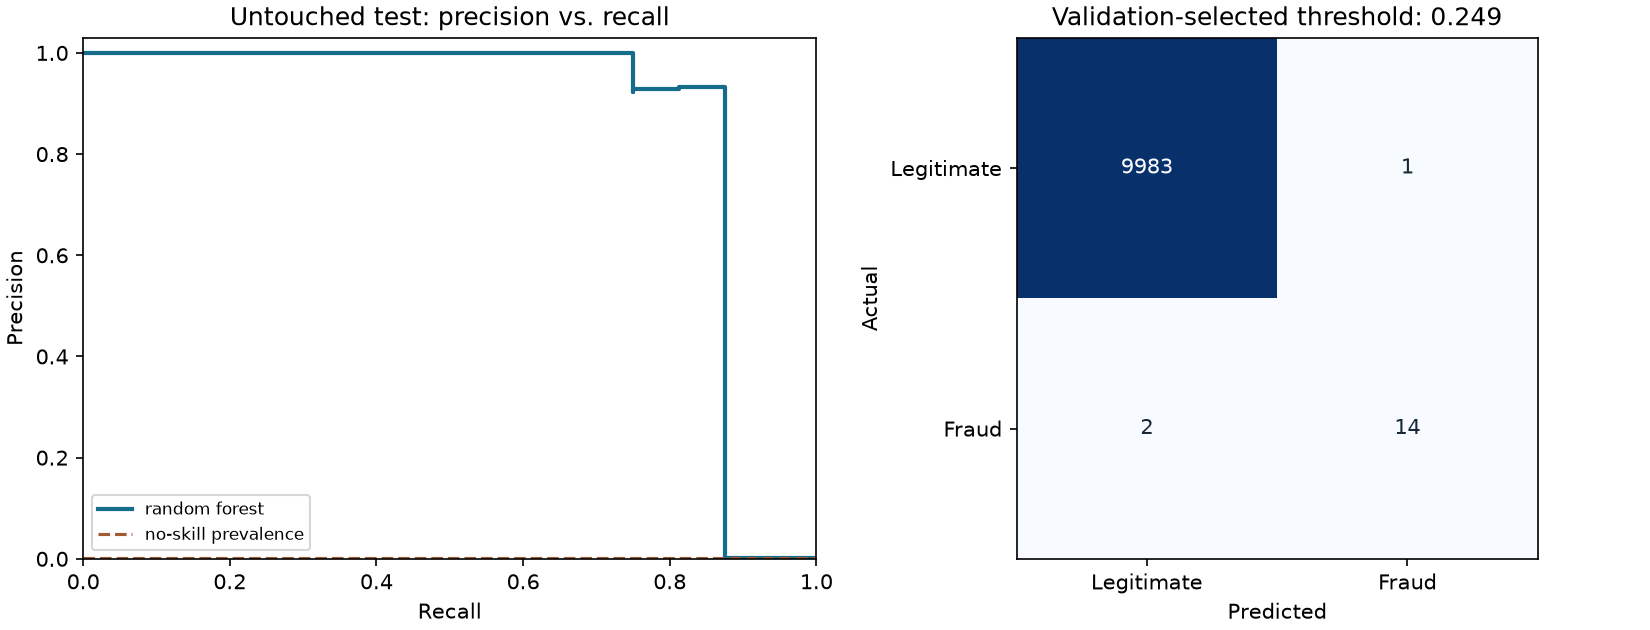

# Credit Card Fraud Detection — reproducible results

Detect fraudulent transactions using the anonymized Worldline/ULB benchmark. This run evaluates 50,000 unique transactions. The default bundled input is a deterministic, prevalence-preserving 50,000-row sample of the deduplicated public dataset. Time orders the split and is excluded from model features. See `data/README.md` for attribution and sampling details.

## Evaluation design

Seed 42. Training, validation, and test row counts: 30,000,
10,000, 10,000.
Preprocessing is fitted inside the training pipeline. Model selection uses validation
average_precision; the decision threshold maximizes validation F2.
The selected model is **random_forest**. No tuning uses the test labels.

## Untouched test results

| Measure | Selected model | Constant-prevalence baseline |
|---|---:|---:|
| Average precision | 0.8666 | 0.0016 |
| ROC AUC | 0.9334 | 0.5000 |
| Log loss (lower is better) | 0.0073 | 0.0119 |
| Brier score (lower is better) | 0.0004 | 0.0016 |
| Precision | 0.9333 | 0.0000 |
| Recall | 0.8750 | 0.0000 |
| F1 | 0.9032 | 0.0000 |
| Accuracy | 0.9997 | 0.9984 |

At threshold **0.2495**, the model produces **15** positive flags:
**14** true positives and **1** false positives.
It misses **2** positives; **9,983** negatives are correctly rejected.
Test positive prevalence is **0.16%**, across 10,000 rows.

![Precision–recall curve and confusion matrix](evaluation.png)

## Interpretation and limits

Average precision and fraud recall are more useful here than accuracy: predicting every transaction as legitimate already achieves very high accuracy. F2 threshold selection weights recall more than precision, but false alerts still consume investigation effort. The test partition covers later transactions, and the small number of fraud cases limits precision of the estimated recall. The benchmark spans only two days in 2013; its anonymized PCA features prevent business-level explanations. These are sample benchmark results, not production fraud-prevention guarantees.

See [all candidate metrics](metrics.csv), [auditable test predictions](predictions.csv),
[split assignments](splits.csv), and [run metadata, input hash, and package versions](metrics.json).
Numbers here are generated by the script, not copied from the historical notebook.


In [4]:
display(Image(filename=str(ROOT / 'results/evaluation.png')))
display(Markdown((ROOT / 'results/REPORT.md').read_text()))

## Auditable outputs

The scores below are held-out predictions, not training predictions.

In [5]:
display(pd.read_csv(ROOT / 'results/predictions.csv').head(10))

,row_id,actual,baseline_score,weighted_logistic_score,random_forest_score,predicted,Time
0,40000,0,0.001967,3.938632e-02,0.000000,0,145465.0
1,40001,0,0.001967,9.987816e-01,0.086996,0,145471.0
2,40002,0,0.001967,7.799660e-03,0.000000,0,145471.0
3,40003,0,0.001967,2.492569e-01,0.012500,0,145475.0
4,40004,0,0.001967,4.671244e-02,0.000000,0,145475.0
5,40005,0,0.001967,4.000000e-07,0.000000,0,145475.0
6,40006,0,0.001967,1.453500e-04,0.000000,0,145476.0
7,40007,0,0.001967,9.713200e-04,0.000000,0,145479.0
8,40008,0,0.001967,1.571553e-01,0.000000,0,145479.0
9,40009,0,0.001967,9.910000e-06,0.000000,0,145485.0


## Inference on new rows

Use the saved preprocessing pipeline and the validation-selected threshold. These three example rows come from the public input; they illustrate the interface and do not provide a new performance estimate.

In [6]:
from predict import predict
display(predict(ROOT / 'examples/new_rows.csv', ROOT / 'results/model.joblib', ROOT / 'results/new_predictions.csv'))

,row_id,positive_score,predicted
0,0,0.0,0
1,1,0.0,0
2,2,0.0,0


## What these results establish

Only 16 fraud cases occur in the test sample and 8 in validation. The observed recall and chosen threshold therefore have substantial sampling uncertainty. Two days of anonymized 2013 transactions cannot establish production performance.

See `data/provenance.json` and `results/metrics.json` for provenance and run settings. The numbers shown here come from this execution.